In [36]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Masuk ke folder utama proyek
PROJECT = "/content/drive/MyDrive/simuteh-2330511058"
os.chdir(PROJECT)

# Membuat folder hasil jika belum tersedia
HASIL = os.path.join(PROJECT, "hasil")
os.makedirs(HASIL, exist_ok=True)

# Memanggil modul dari folder src
sys.path.append(PROJECT)

from src.praproses import praproses, simpan_param
from src.utils_cv import kontras_bercak

print("Folder proyek:", os.getcwd())
print("Folder hasil:", HASIL)
print("Folder hasil tersedia:", os.path.exists(HASIL))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder proyek: /content/drive/MyDrive/simuteh-2330511058
Folder hasil: /content/drive/MyDrive/simuteh-2330511058/hasil
Folder hasil tersedia: True


In [37]:
import sys
import importlib.util

path = "/content/drive/MyDrive/simuteh-2330511058/src/utils_tepi.py"

spec = importlib.util.spec_from_file_location("utils_tepi", path)
utils_tepi = importlib.util.module_from_spec(spec)
sys.modules["utils_tepi"] = utils_tepi
spec.loader.exec_module(utils_tepi)

from utils_tepi import (
    tepi_acuan,
    skor_tepi,
    iou,
    mask_daun_awal,
    bercak_awal
)

print("Semua fungsi berhasil diimpor!")

Semua fungsi berhasil diimpor!


In [38]:
import sys, json
sys.path.insert(0, "../src")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import (
    tepi_acuan, skor_tepi, iou,
    mask_daun_awal, bercak_awal
)

##**1.2 Persiapan dan gradien Sobel**

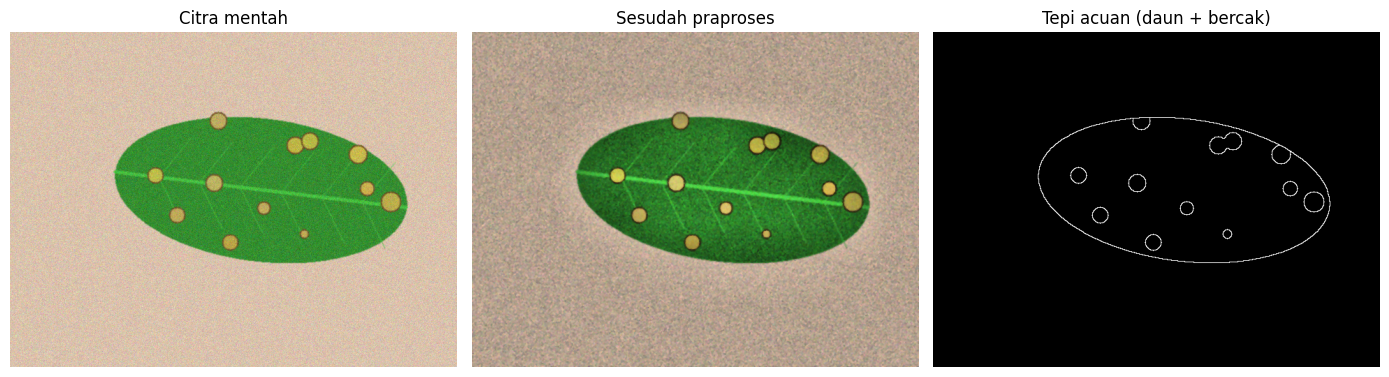

In [43]:
import sys
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mengakses folder src
sys.path.append("../src")

# Import modul
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import (
    tepi_acuan,
    skor_tepi,
    iou,
    mask_daun_awal,
    bercak_awal
)

# Pengaturan tampilan Pandas
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

# Membaca parameter hasil Evaluasi P1-P4
PARAM = json.load(open("hasil/param_praproses.json"))

# Membaca label dataset
label = pd.read_csv("data/sintetis/label.csv")

# Fungsi untuk memuat citra dan mask
def muat(nama):
    img = baca(f"data/sintetis/citra/{nama}")
    md = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)

    return img, md, mb

# Memuat satu citra contoh
img, md, mb = muat("teh_041.png")

# Melakukan praproses
pra = praproses(img, PARAM)

# Membuat tepi acuan dari mask daun dan mask bercak
acuan = cv2.bitwise_or(
    tepi_acuan(md),
    tepi_acuan(mb)
)

# Menampilkan citra
tampil(
    [img, pra, acuan],
    [
        "Citra mentah",
        "Sesudah praproses",
        "Tepi acuan (daun + bercak)"
    ]
)

##**Kode 1.2 Gradien Sobel manual: Gx, Gy, magnitudo, dan arah**

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 710.7


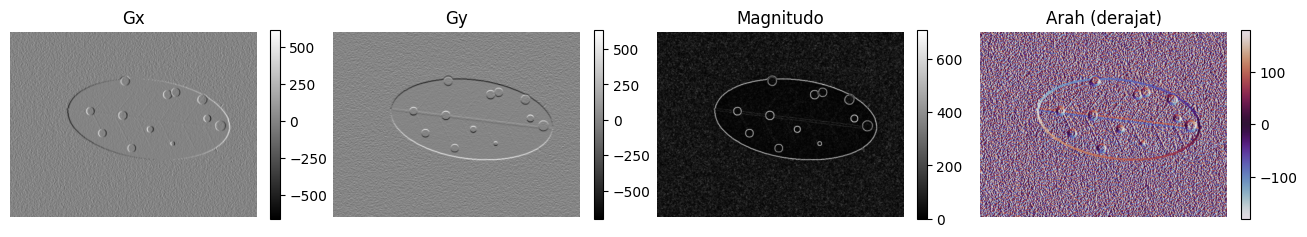

In [44]:
g = pra[:, :, 2].astype(np.float32) # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx) # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky) # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))
# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))
plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah,
"Arah (derajat)")]):
 plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else
"gray")
 plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)

##**Langkah 1.3 Empat operator pada satu citra**

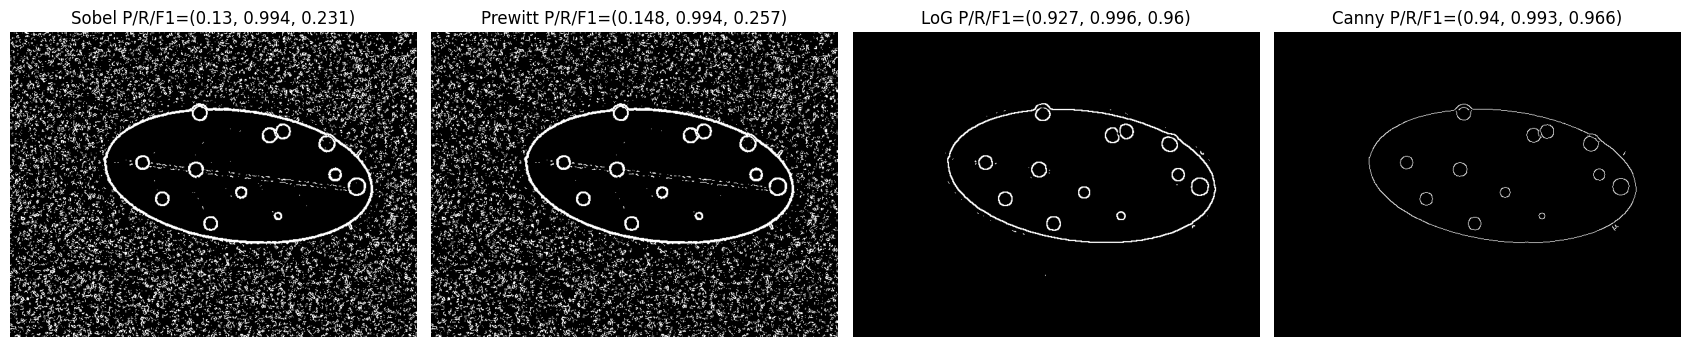

In [45]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(
        cv2.Sobel(g, cv2.CV_32F, 1, 0),
        cv2.Sobel(g, cv2.CV_32F, 0, 1)
    )
    return ((m > T) * 255).astype(np.uint8)


def tepi_prewitt(g, T=75):
    kx = np.array([
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1]
    ], np.float32)

    g = g.astype(np.float32)

    m = np.hypot(
        cv2.filter2D(g, -1, kx),
        cv2.filter2D(g, -1, kx.T)
    )
    return ((m > T) * 255).astype(np.uint8)


def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(
        cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma),
        cv2.CV_32F
    )

    mn, mx = (
        cv2.erode(L, np.ones((3, 3))),
        cv2.dilate(L, np.ones((3, 3)))
    )

    return (
        ((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255
    ).astype(np.uint8)


def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)

    return cv2.Canny(g, lo, hi)


metode = {
    "Sobel": tepi_sobel,
    "Prewitt": tepi_prewitt,
    "LoG": tepi_log,
    "Canny": tepi_canny
}

g = pra[:, :, 2]

hasil = {
    nm: f(g)
    for nm, f in metode.items()
}

tampil(
    list(hasil.values()),
    [
        f"{nm} P/R/F1={skor_tepi(e, acuan)}"
        for nm, e in hasil.items()
    ],
    ukuran=(17, 3.6)
)

##**Langkah 1.4 Perbandingan menyeluruh**

In [47]:
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)

    ac = cv2.bitwise_or(
        tepi_acuan(md),
        tepi_acuan(mb)
    )

    for sumber, im in [
        ("mentah", img),
        ("praproses", praproses(img, PARAM))
    ]:
        for kanal, g in [
            ("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)),
            ("R", im[:, :, 2])
        ]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)

                baris.append([
                    d.kondisi_cahaya,
                    sumber,
                    kanal,
                    nm,
                    p,
                    r,
                    f1
                ])


tabel_tepi = pd.DataFrame(
    baris,
    columns=[
        "kondisi",
        "sumber",
        "kanal",
        "metode",
        "P",
        "R",
        "F1"
    ]
)

ringkas = tabel_tepi.groupby(
    ["sumber", "kanal", "metode"]
)[["P", "R", "F1"]].mean().round(3)

print(ringkas)

tabel_tepi.to_csv(
    "hasil/p5_tabel_tepi.csv",
    index=False
)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.761  0.751  0.756
                LoG      0.619  0.997  0.756
                Prewitt  0.806  0.962  0.867
                Sobel    0.773  0.969  0.849
          R     Canny    0.980  0.983  0.981
                LoG      0.883  0.997  0.928
                Prewitt  0.595  0.996  0.692
                Sobel    0.540  0.996  0.640
praproses Gray  Canny    0.675  0.943  0.780
                LoG      0.528  0.996  0.680
                Prewitt  0.558  0.996  0.705
                Sobel    0.528  0.996  0.677
          R     Canny    0.934  0.989  0.959
                LoG      0.808  0.997  0.875
                Prewitt  0.473  0.997  0.598
                Sobel    0.428  0.997  0.556


<Figure size 1000x500 with 0 Axes>

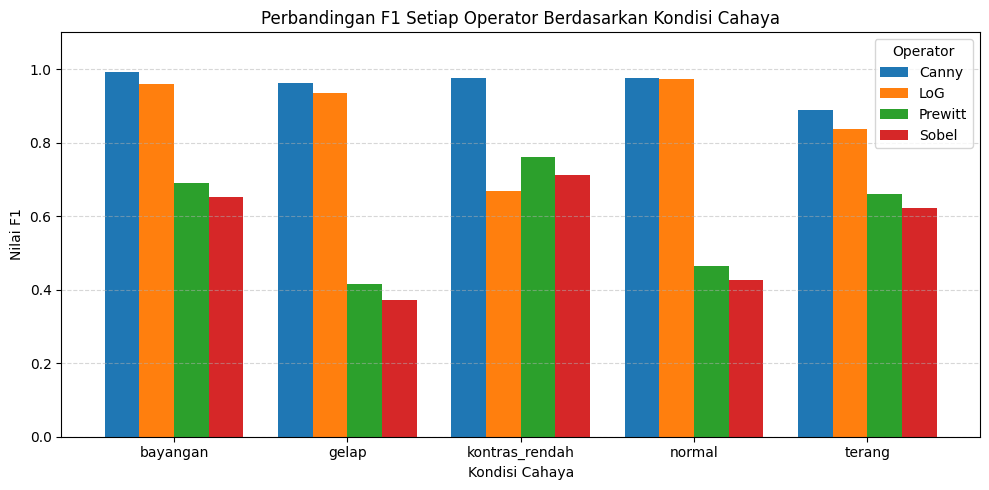

Grafik berhasil disimpan di hasil/p5_f1_kondisi.png


In [48]:
# Filter data kanal R sesudah praproses
data_f1 = tabel_tepi[
    (tabel_tepi["sumber"] == "praproses") &
    (tabel_tepi["kanal"] == "R")
]

# Menghitung rata-rata F1 berdasarkan kondisi cahaya dan metode
ringkas_f1 = data_f1.groupby(
    ["kondisi", "metode"]
)["F1"].mean().unstack()

# Membuat grafik batang
plt.figure(figsize=(10, 5))

ringkas_f1.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

plt.title("Perbandingan F1 Setiap Operator Berdasarkan Kondisi Cahaya")
plt.xlabel("Kondisi Cahaya")
plt.ylabel("Nilai F1")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title="Operator")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Menyimpan grafik
plt.savefig(
    "hasil/p5_f1_kondisi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grafik berhasil disimpan di hasil/p5_f1_kondisi.png")

##**Kode 2.1 Eksperimen sigma dan ambang Canny.**

In [49]:
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)

    g = praproses(img, PARAM)[:, :, 2]

    ad = tepi_acuan(md)
    ab = tepi_acuan(mb)

    ac = cv2.bitwise_or(ad, ab)

    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [
            (30, 90),
            (50, 150),
            (100, 200)
        ]:
            e = tepi_canny(g, lo, hi, sigma)

            p, r, f1 = skor_tepi(e, ac)

            r_bercak = skor_tepi(e, ab)[1]  # recall khusus tepi bercak

            baris.append([
                d.kelas,
                sigma,
                f"{lo}/{hi}",
                p,
                r,
                f1,
                r_bercak
            ])


canny = pd.DataFrame(
    baris,
    columns=[
        "kelas",
        "sigma",
        "ambang",
        "P",
        "R",
        "F1",
        "R_bercak"
    ]
)


print(
    canny.groupby(
        ["sigma", "ambang"]
    )[["P", "R", "F1", "R_bercak"]].mean().round(3)
)


print(
    canny.pivot_table(
        index=["sigma", "ambang"],
        columns="kelas",
        values="R_bercak"
    ).round(3)
)

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.532  0.994  0.624     0.979
      30/90    0.019  0.997  0.038     0.989
      50/150   0.122  0.995  0.193     0.983
1.0   100/200  0.966  0.993  0.979     0.977
      30/90    0.258  0.994  0.356     0.981
      50/150   0.839  0.994  0.898     0.979
2.0   100/200  0.786  0.789  0.788     0.735
      30/90    0.934  0.989  0.959     0.959
      50/150   0.976  0.982  0.979     0.909
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.972   0.986
      30/90    0.988   0.990
      50/150   0.980   0.986
1.0   100/200  0.969   0.985
      30/90    0.974   0.987
      50/150   0.971   0.987
2.0   100/200  0.752   0.719
      30/90    0.946   0.971
      50/150   0.911   0.908


##**Kode 2.2 Ambang Canny otomatis berbasis.**

In [50]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)

    return cv2.Canny(
        g,
        int(max(0, (1 - s) * v)),
        int(min(255, (1 + s) * v))
    )
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)

    ac = cv2.bitwise_or(
        tepi_acuan(md),
        tepi_acuan(mb)
    )
    pra_ = praproses(img, PARAM)

    for kanal, g in [
        ("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)),
        ("R", pra_[:, :, 2])
    ]:
        baris.append([
            d.kondisi_cahaya,
            kanal,
            "otomatis",
            skor_tepi(canny_otomatis(g), ac)[2],
            np.median(g)
        ])

        baris.append([
            d.kondisi_cahaya,
            kanal,
            "tetap 30/90",
            skor_tepi(tepi_canny(g), ac)[2],
            np.median(g)
        ])
auto = pd.DataFrame(
    baris,
    columns=[
        "kondisi",
        "kanal",
        "ambang",
        "F1",
        "median"
    ]
)
print(
    auto.pivot_table(
        index=["kanal", "ambang"],
        columns="kondisi",
        values="F1"
    ).round(3)
)
print(
    auto.groupby(
        ["kanal", "kondisi"]
    )["median"].mean().round(1)
)

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.515  0.531           0.864   0.699   0.845
      tetap 30/90     0.762  0.728           0.930   0.732   0.749
R     otomatis        0.450  0.431           0.851   0.631   0.914
      tetap 30/90     0.992  0.962           0.976   0.974   0.890
kanal  kondisi       
Gray   bayangan          115.4
       gelap             139.0
       kontras_rendah    150.2
       normal            165.0
       terang            193.1
R      bayangan          120.5
       gelap             155.0
       kontras_rendah    152.5
       normal            175.8
       terang            198.1
Name: median, dtype: float64


Canny Persentil

In [51]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    # 1. Penghalusan Gaussian
    halus = cv2.GaussianBlur(
        g.astype(np.float32),
        (0, 0),
        sigma
    )

    # 2. Menghitung magnitudo Sobel
    gx = cv2.Sobel(halus, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(halus, cv2.CV_32F, 0, 1, ksize=3)

    mag = np.hypot(gx, gy)

    # 3. Menentukan ambang berdasarkan persentil
    atas = np.percentile(mag, q)
    bawah = rasio * atas

    # 4. Deteksi tepi Canny
    return cv2.Canny(
        halus.astype(np.uint8),
        int(bawah),
        int(atas)
    )


baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)

    ac = cv2.bitwise_or(
        tepi_acuan(md),
        tepi_acuan(mb)
    )

    pra_ = praproses(img, PARAM)

    for kanal, g in [
        ("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)),
        ("R", pra_[:, :, 2])
    ]:
        for q in [90, 95, 98]:
            e = canny_persentil(g, q)

            p, r, f1 = skor_tepi(e, ac)

            r_bercak = skor_tepi(e, tepi_acuan(mb))[1]

            baris.append([
                d.kondisi_cahaya,
                kanal,
                q,
                p,
                r,
                f1,
                r_bercak
            ])


persentil = pd.DataFrame(
    baris,
    columns=[
        "kondisi",
        "kanal",
        "q",
        "P",
        "R",
        "F1",
        "R_bercak"
    ]
)


print(
    persentil.groupby(
        ["kanal", "q"]
    )[["P", "R", "F1", "R_bercak"]].mean().round(3)
)


print(
    persentil.pivot_table(
        index=["kanal", "q"],
        columns="kondisi",
        values="F1"
    ).round(3)
)

              P      R     F1  R_bercak
kanal q                                
Gray  90  0.030  0.950  0.058     0.771
      95  0.161  0.948  0.256     0.762
      98  0.621  0.941  0.745     0.730
R     90  0.032  0.990  0.062     0.959
      95  0.101  0.989  0.164     0.958
      98  0.905  0.988  0.940     0.956
kondisi   bayangan  gelap  kontras_rendah  normal  terang
kanal q                                                  
Gray  90     0.063  0.061           0.056   0.057   0.056
      95     0.246  0.314           0.157   0.323   0.238
      98     0.767  0.763           0.720   0.735   0.741
R     90     0.068  0.063           0.057   0.063   0.060
      95     0.154  0.116           0.139   0.147   0.262
      98     0.992  0.973           0.898   0.983   0.852


kanal            Gray      R
kondisi                     
bayangan        870.5    0.0
gelap           917.5    0.0
kontras_rendah  118.2    0.0
normal          823.0  243.5
terang          891.5  211.5


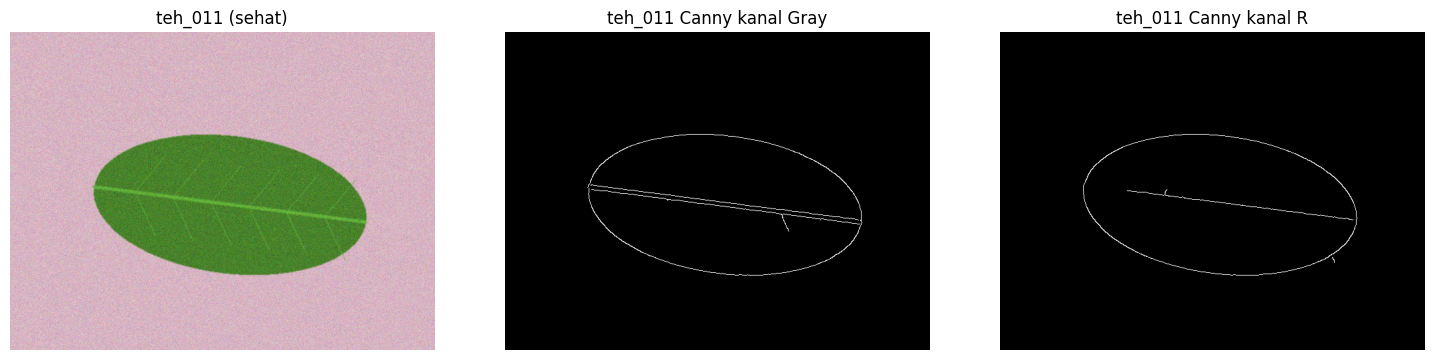

In [52]:
baris, panel, judul = [], [], []

for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)

    pra_ = praproses(img, PARAM)

    dalam = cv2.erode(
        md,
        np.ones((7, 7), np.uint8)
    ) > 0  # bagian dalam daun

    for kanal, g in [
        ("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)),
        ("R", pra_[:, :, 2])
    ]:
        e = tepi_canny(g)

        baris.append([
            d.kondisi_cahaya,
            kanal,
            int(((e > 0) & dalam).sum())
        ])

        if d.nama_file == "teh_011.png":
            panel.append(e)
            judul.append(f"teh_011 Canny kanal {kanal}")


sehat = pd.DataFrame(
    baris,
    columns=[
        "kondisi",
        "kanal",
        "piksel_tepi_di_dalam_daun"
    ]
)


print(
    sehat.pivot_table(
        index="kondisi",
        columns="kanal",
        values="piksel_tepi_di_dalam_daun"
    ).round(1)
)


tampil(
    [muat("teh_011.png")[0]] + panel,
    ["teh_011 (sehat)"] + judul,
    ukuran=(15, 3.6)
)